# 05 — VECM, señales, sizing y búsqueda de umbrales

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · **Guía:** `docs/instrucciones/05_vecm_senales.md`

**Objetivo.** Convertir el z-score prior del filtro 2 en posiciones por activo:

1. **VECM en train:** qué activos corrigen cuando el spread se abre (α) y a qué velocidad (βᵀα).
2. **Regla de bandas** sobre z_t con θ = (z_entrada, z_salida, z_stop, h_max), la PFA de la sesión 11.
3. **Sizing:** 80 % del capital repartido según |β̂_t| (`strategy/sizing.py`, escrito por JME para el motor).
4. **Grid search de θ solo en train**, con el Sharpe neto de costos del motor de la parte 06.

> Este notebook solo **muestra**: la lógica vive en `strategy/` y es la misma que ejecuta `python main.py`. La rejilla,
> el objetivo y la regla se registraron en `docs/decisiones.md` **antes** de ver resultados.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from kalman.weights_filter import ect_comparison
from main import ARTIFACTS, FIGURES
from strategy.optimization import MIN_TRADES, compare_static_dynamic, evaluate_by_split
from strategy.signals import SignalRule, generate_signals
from strategy.sizing import POSITION_FRACTION, target_shares

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

prices = pd.read_parquet(ARTIFACTS / "prices.parquet")
split = prices.pop("split")
kf1 = pd.read_parquet(ARTIFACTS / "kf1_weights.parquet")
signals = pd.read_parquet(ARTIFACTS / "signals.parquet")
grid = pd.read_csv(ARTIFACTS / "grid_search.csv")
johansen = json.loads((ARTIFACTS / "johansen_summary.json").read_text())
vecm = json.loads((ARTIFACTS / "vecm_summary.json").read_text())
strategy = json.loads((ARTIFACTS / "params.json").read_text())["strategy"]
kf2_params = json.loads((ARTIFACTS / "params.json").read_text())["kf2"]
tickers = johansen["tickers"]
rule = SignalRule(strategy["z_entry"], strategy["z_exit"], strategy["z_stop"], strategy["max_holding"])
print("grupo:", "-".join(tickers), "| θ congelado:", rule)

grupo: GLD-GDX-AEM-FNV | θ congelado: SignalRule(z_entry=1.0, z_exit=0.5, z_stop=3.0, max_holding=51)


## 1. VECM en entrenamiento

$$\Delta \ln P_t = \alpha\,(\tilde\beta^\top \ln P_{t-1} - c) + \Gamma_1\,\Delta \ln P_{t-1} + \varepsilon_t$$

Se estima con `statsmodels` con `deterministic="co"`, que es el mismo caso que `det_order = 0` de Johansen, con r = 1 y
k_ar_diff = 1 como en la parte 02. Así el β que estima el VECM **es exactamente** el β̃ de Johansen (se verifica con
tolerancia 1e-6), y α queda en la misma escala.

In [2]:
table = pd.DataFrame({"β̃ (Johansen)": vecm["beta_normalized"], "α": vecm["alpha"], "error est.": vecm["alpha_stderr"],
                      "t": vecm["alpha_tstat"]})
display(table)
print(f"βᵀα = {vecm['beta_alpha']:.4f}  →  corrige hacia el equilibrio (−2 < βᵀα < 0): {vecm['error_correction']}")
print(f"vida media implícita del VECM: −ln 2 / ln(1 + βᵀα) = {vecm['half_life_days']:.1f} días")
print(f"α significativo al 5 %: {vecm['alpha_significant_5pct']}")

,β̃ (Johansen),α,error est.,t
GLD,1,-0.01499,0.004655,-3.221
GDX,-0.5686,0.004056,0.01246,0.3257
AEM,0.4004,-0.009725,0.01336,-0.7281
FNV,-0.3709,0.0128,0.01071,1.196


βᵀα = -0.0259  →  corrige hacia el equilibrio (−2 < βᵀα < 0): True
vida media implícita del VECM: −ln 2 / ln(1 + βᵀα) = 26.4 días
α significativo al 5 %: ['GLD']


**Qué dicen los α.** Con ECT = ln GLD − 0.569 ln GDX + 0.400 ln AEM − 0.371 ln FNV − c, un ECT positivo significa
que el oro está caro frente a las mineras. El único α significativo es el de **GLD (−0.015, t ≈ −3.2)**: cuando el spread
se abre, **el oro es el que corrige** hacia las mineras, y no al revés. Los α de las mineras no son distinguibles de cero.

**Tres estimaciones de la velocidad de reversión, todas en train:**

| Fuente | Vida media |
|---|---|
| OU sobre el spread de Johansen (parte 02) | 25.3 días |
| VECM, βᵀα | 26.4 días |
| φ del filtro 2 sobre el ECT dinámico (parte 04) | 21.2 días |

Coinciden en el orden de magnitud: el spread cierra la mitad de una desviación en 4 a 5 semanas. El holding máximo usa
la de la parte 02, que es la misma que calibra los filtros 1 y 2.

**¿Qué aporta el VECM si ya tenemos Kalman?** Confirma que la relación de Johansen es de corrección de error y no solo
estacionaria por casualidad, dice qué activo hace el ajuste y da una vida media independiente del filtro.

## 2. Qué serie alimenta al filtro 2: ECT dinámico contra estático

El profesor aclaró que el "residual del VECM" es el **ECT que el filtro 1 produce día a día** (β̂_{t|t−1}ᵀ ln P_t − ĉ),
no ε_t. La versión estática usa el β̃ y la c de Johansen congelados en train. Fuera de muestra el estático se desplaza:
en validación su media es 0.44, y el dinámico sigue más cerca de cero.

mean     std  adf_stat  adf_pvalue  half_life
ect     split                                                        
static  train      0.0005177  0.0433    -4.432   0.0002605      24.51
        test        -0.02651  0.0411    -2.078      0.2535      46.26
        validation    0.4351  0.1348    -2.346      0.1576        112
dynamic train      -0.001215 0.04025    -4.766   6.316e-05      21.18
        test       0.0005503  0.0376    -2.392       0.144      37.01
        validation    0.1097 0.08207   -0.8559      0.8021      200.3

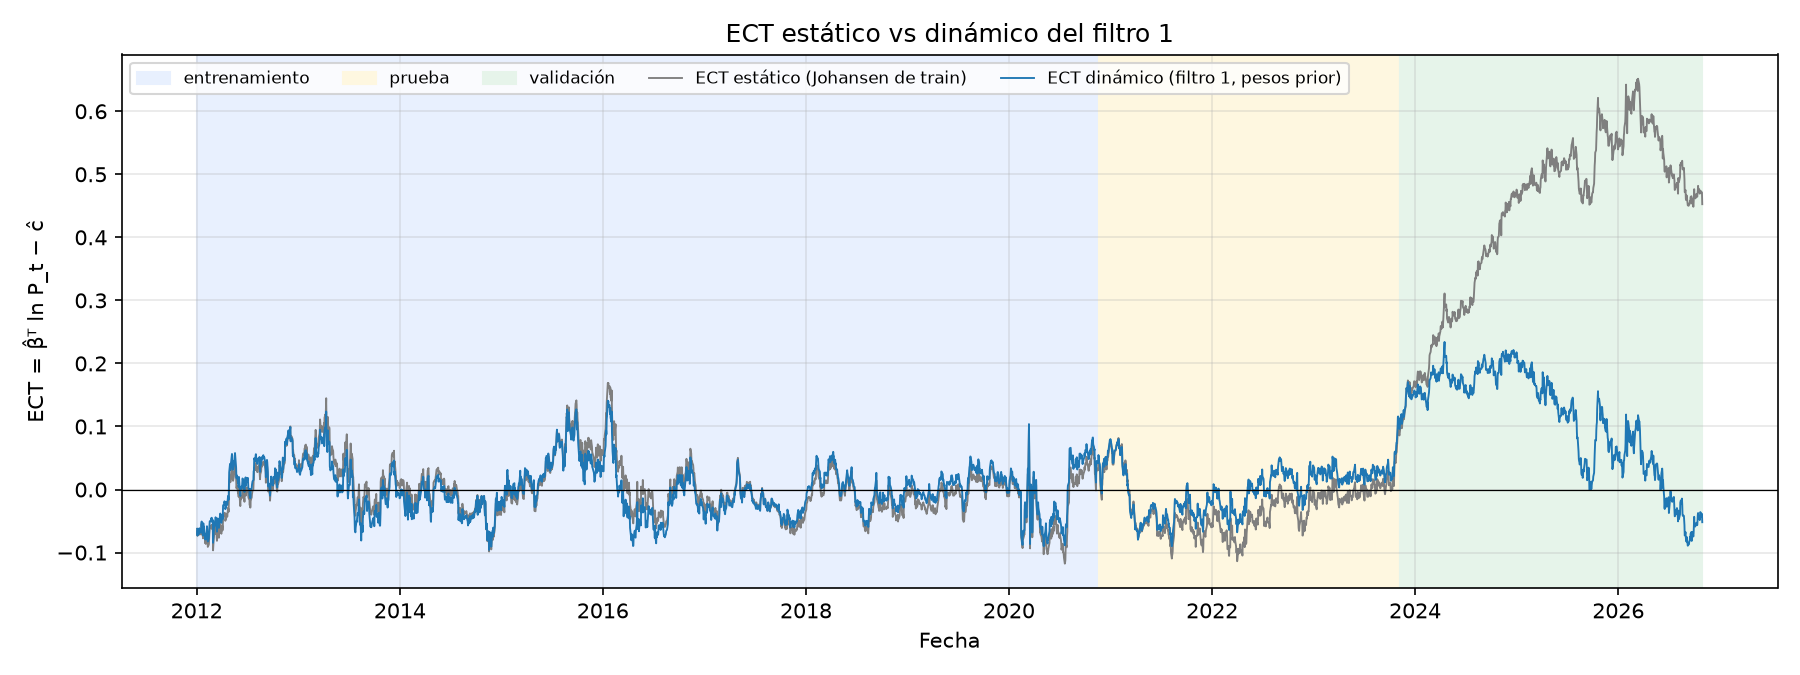

In [3]:
display(ect_comparison(kf1).set_index(["ect", "split"]))
display(Image(FIGURES / "ect_estatico_vs_dinamico.png"))

## 3. La regla de señales

Decidida al cierre de t con z_t prior; el motor la ejecuta al cierre de t + 1.

| Estado | Condición | Decisión |
|---|---|---|
| plano | −z_stop < z_t < −z_entrada | **largo** el spread (comprar β̃ > 0: GLD y AEM; vender GDX y FNV) |
| plano | z_entrada < z_t < z_stop | **corto** el spread |
| con posición | \|z_t\| ≥ z_stop | cerrar por **stop** |
| con posición | h_t ≥ h_max | cerrar por **holding** |
| largo (corto) | z_t ≥ −z_salida (z_t ≤ z_salida) | cerrar por **salida** |

Las cuatro decisiones que la clase deja abiertas (`docs/decisiones.md`):

- **Prioridad:** stop > holding > salida.
- **Salida direccional:** si z salta al otro lado sin pasar por la banda, también se cierra.
- **No se reabre el mismo día de un cierre.**
- **Rearme después de un stop o holding:** esa dirección no vuelve a entrar hasta que |z_t| < z_entrada.

Ejemplo con un z inventado y θ = (1, 0.5, 3, h_max = 5):

In [4]:
toy = pd.Series([0.2, -1.3, -1.6, -0.8, -0.3,      # entra largo y sale al llegar a −0.5
                 1.4, 2.2, 3.1, 2.6, 2.0, 0.7,     # entra corto, stop en 3.1, no reentra hasta |z| < 1
                 1.2, 1.3, 1.5, 1.6, 1.8, 1.9, 1.7],  # entra corto, cierra por holding a los 5 días
                index=pd.RangeIndex(18, name="día"))
demo = generate_signals(toy, SignalRule(1.0, 0.5, 3.0, 5))
display(demo.assign(z=toy)[["z", "signal", "holding_days", "exit_reason"]].T)

día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
z,0.2,-1.3,-1.6,-0.8,-0.3,1.4,2.2,3.1,2.6,2,0.7,1.2,1.3,1.5,1.6,1.8,1.9,1.7
signal,0,1,1,1,0,-1,-1,0,0,0,0,-1,-1,-1,-1,-1,0,0
holding_days,0,0,1,2,0,0,1,0,0,0,0,0,1,2,3,4,0,0
exit_reason,,,,,salida,,,stop,,,,,,,,,holding,


## 4. Sizing: 80 % del capital repartido según |β̂_t|

$$N_i = 0.8\,V_t\,\frac{|\hat\beta_i|}{\sum_j|\hat\beta_j|},\qquad q_i = d_t\,\mathrm{sgn}(\hat\beta_i)\,\frac{N_i}{P_i}$$

Como β se estimó sobre log-precios, β_i es la exposición del spread al rendimiento del activo i, así que el nocional en
dólares ∝ |β_i| reproduce el spread. Verificación con los β̂ y precios del primer día con señal en validación:

In [5]:
day = signals.index[(signals["split"] == "validation") & (signals["signal"] != 0)][0]
beta = signals.loc[day, [f"beta_{t}" for t in tickers]].to_numpy(dtype=float)
d = int(signals.loc[day, "signal"])
shares = target_shares(d, beta, prices.loc[day, tickers].to_numpy(), 1_000_000)
notional = shares * prices.loc[day, tickers].to_numpy()
display(pd.DataFrame({"β̂_t": beta, "acciones": shares, "nocional $": notional}, index=tickers))
print(f"{day.date()}: dirección {d:+d} ({'largo' if d > 0 else 'corto'} el spread)")
print(f"nocional bruto = {np.abs(notional).sum():,.0f} = {POSITION_FRACTION:.0%} de $1,000,000")

,β̂_t,acciones,nocional $
GLD,1,-1888,-3.427e+05
GDX,-0.5671,7296,1.943e+05
AEM,0.3988,-3038,-1.366e+05
FNV,-0.3688,1080,1.264e+05


2023-11-09: dirección -1 (corto el spread)
nocional bruto = 800,000 = 80% de $1,000,000


## 5. Grid search en entrenamiento

Rejilla y objetivo registrados antes de correrla:

- **Rejilla:** z_entrada ∈ {1, 1.25, 1.5, 1.75, 2, 2.5}, z_salida ∈ {0, 0.25, 0.5}, z_stop ∈ {2.5, 3, 3.5, 4} y
  k ∈ {1, 2, 3}, con h_max = k · 25.3 días.
- **Objetivo:** Sharpe neto anualizado de `run_backtest` con costos completos y rebalanceo diario.
- **Tramo:** train, después de los burn-in de ambos filtros.
- **Mínimo de operaciones:** 10.

Hay umbrales de entrada menores que 2 porque en train solo 1.8 % de los días tienen |z| > 2.

In [6]:
print(f"combinaciones: {len(grid)}; con ≥ {MIN_TRADES} operaciones: {int(grid['valid'].sum())}")
print(f"tramo: {strategy['train_period'][0]} → {strategy['train_period'][1]}")
cols = ["z_entry", "z_exit", "z_stop", "holding_k", "max_holding", "sharpe_net", "net_return", "max_drawdown",
        "n_trades", "win_rate", "exits_salida", "exits_stop", "exits_holding", "commission"]
display(grid.loc[grid["valid"], cols].head(10))
print("Sharpe neto de las combinaciones válidas:")
print(grid.loc[grid["valid"], "sharpe_net"].describe()[["min", "25%", "50%", "75%", "max"]].round(2).to_string())

combinaciones: 207; con ≥ 10 operaciones: 153
tramo: 2013-04-08 → 2020-11-19


,z_entry,z_exit,z_stop,holding_k,max_holding,sharpe_net,net_return,max_drawdown,n_trades,win_rate,exits_salida,exits_stop,exits_holding,commission
0,1,0.5,3,2,51,0.7709,0.2389,-0.03867,35,0.8,30,0,5,8.581e+04
1,1,0.5,3.5,2,51,0.7709,0.2389,-0.03867,35,0.8,30,0,5,8.581e+04
2,1,0.5,4,2,51,0.7709,0.2389,-0.03867,35,0.8,30,0,5,8.581e+04
3,1,0.5,3,3,76,0.7124,0.2264,-0.04993,33,0.8788,31,0,2,8.111e+04
4,1,0.5,3.5,3,76,0.7124,0.2264,-0.04993,33,0.8788,31,0,2,8.111e+04
5,1,0.5,4,3,76,0.7124,0.2264,-0.04993,33,0.8788,31,0,2,8.111e+04
6,1,0,3,2,51,0.7108,0.2394,-0.03622,28,0.6429,19,0,9,7.444e+04
7,1,0,3.5,2,51,0.7108,0.2394,-0.03622,28,0.6429,19,0,9,7.444e+04
8,1,0,4,2,51,0.7108,0.2394,-0.03622,28,0.6429,19,0,9,7.444e+04
9,1,0.5,2.5,2,51,0.6999,0.2096,-0.0502,35,0.7714,29,1,5,8.434e+04


Sharpe neto de las combinaciones válidas:
min   0.13
25%   0.46
50%   0.55
75%   0.63
max   0.77


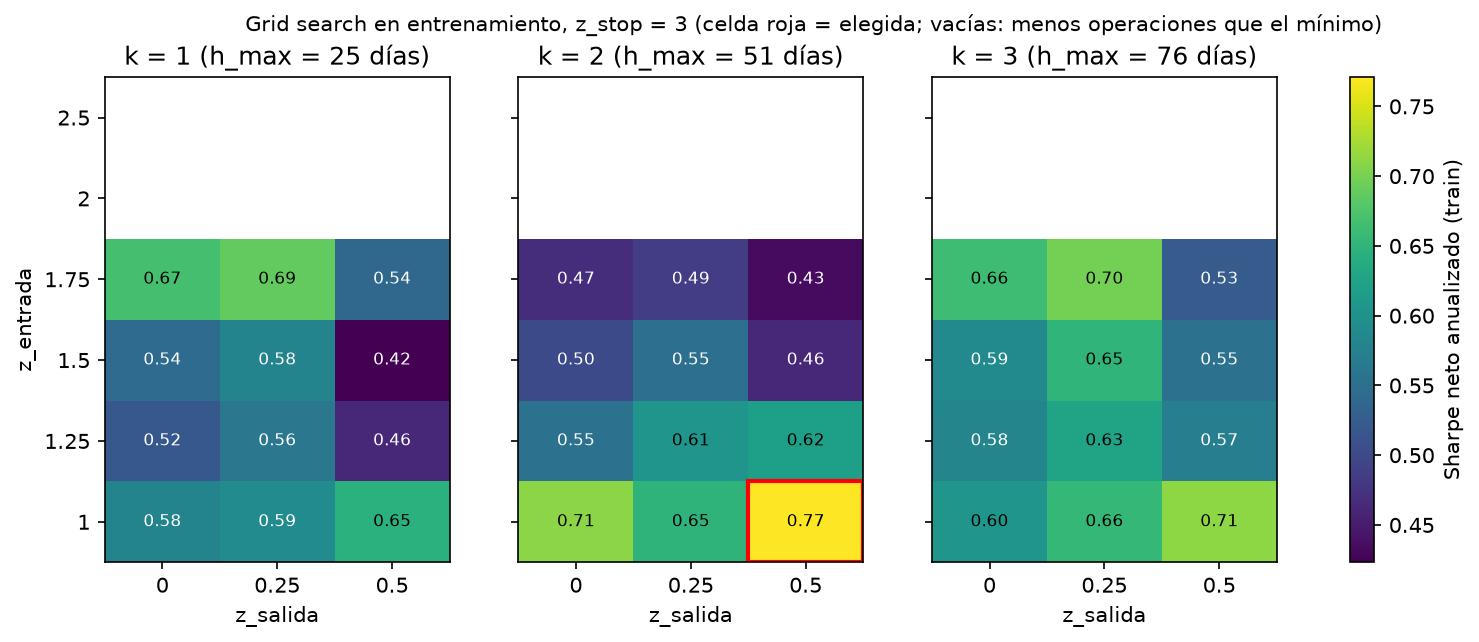

In [7]:
display(Image(FIGURES / "grid_search_heatmap.png"))

**Cómo leer el grid:**

- **Los stops empatan.** En train el stop nunca se toca con z_stop ≥ 3, así que 3, 3.5 y 4 dan el mismo resultado.
  El desempate declarado elige el más estricto (3), que es el que protege en validación.
- **El óptimo está en el borde de la rejilla:** z_entrada = 1. La rejilla **no se amplió** después de verlo, porque eso
  sería ajustar la búsqueda a los datos. Sí hay combinaciones cercanas con Sharpe parecido, por ejemplo
  z_entrada = 1.75 con k = 3 da 0.70. Se reporta como limitación.
- **Sensibilidad.** Todas las combinaciones válidas tienen Sharpe neto positivo en train, entre 0.13 y 0.77. El
  resultado depende más de entrar seguido que del valor exacto de cada umbral.
- **Las celdas vacías** son los umbrales de entrada de 2 y 2.5, que dan menos de 10 operaciones en siete años.
- **Costos.** Con el θ elegido, las comisiones se llevan el 26 % del P&L bruto en train ($85.8 mil de $327 mil): 4
  patas, entrada, salida y rebalanceo diario. El préstamo es menor ($2.7 mil). La parte 06 compara el rebalanceo
  diario contra la banda de no-rebalanceo.

## 6. Parámetros congelados (`params.json` → `strategy`)

Se fijan aquí, con train, antes de mirar prueba y validación.

In [8]:
print(json.dumps({k: v for k, v in strategy.items() if k != "grid"}, indent=2, ensure_ascii=False))

{
  "z_entry": 1.0,
  "z_exit": 0.5,
  "z_stop": 3.0,
  "max_holding": 51,
  "holding_k": 2,
  "half_life_days": 25.33555,
  "objective": "sharpe_net: Sharpe neto anualizado en train (rf = 0, √252), rebalanceo diario, costos completos",
  "train_objective": 0.77094748,
  "train_trades": 35,
  "train_period": [
    "2013-04-08",
    "2020-11-19"
  ]
}


## 7. Figura 6 — z-score con los umbrales elegidos

En validación el spread se desplaza y z pasa meses arriba de 2. La estrategia entra en corto, el stop la saca, y el
rearme impide que vuelva a entrar mientras z siga lejos. Por eso se queda plana casi todo 2024.

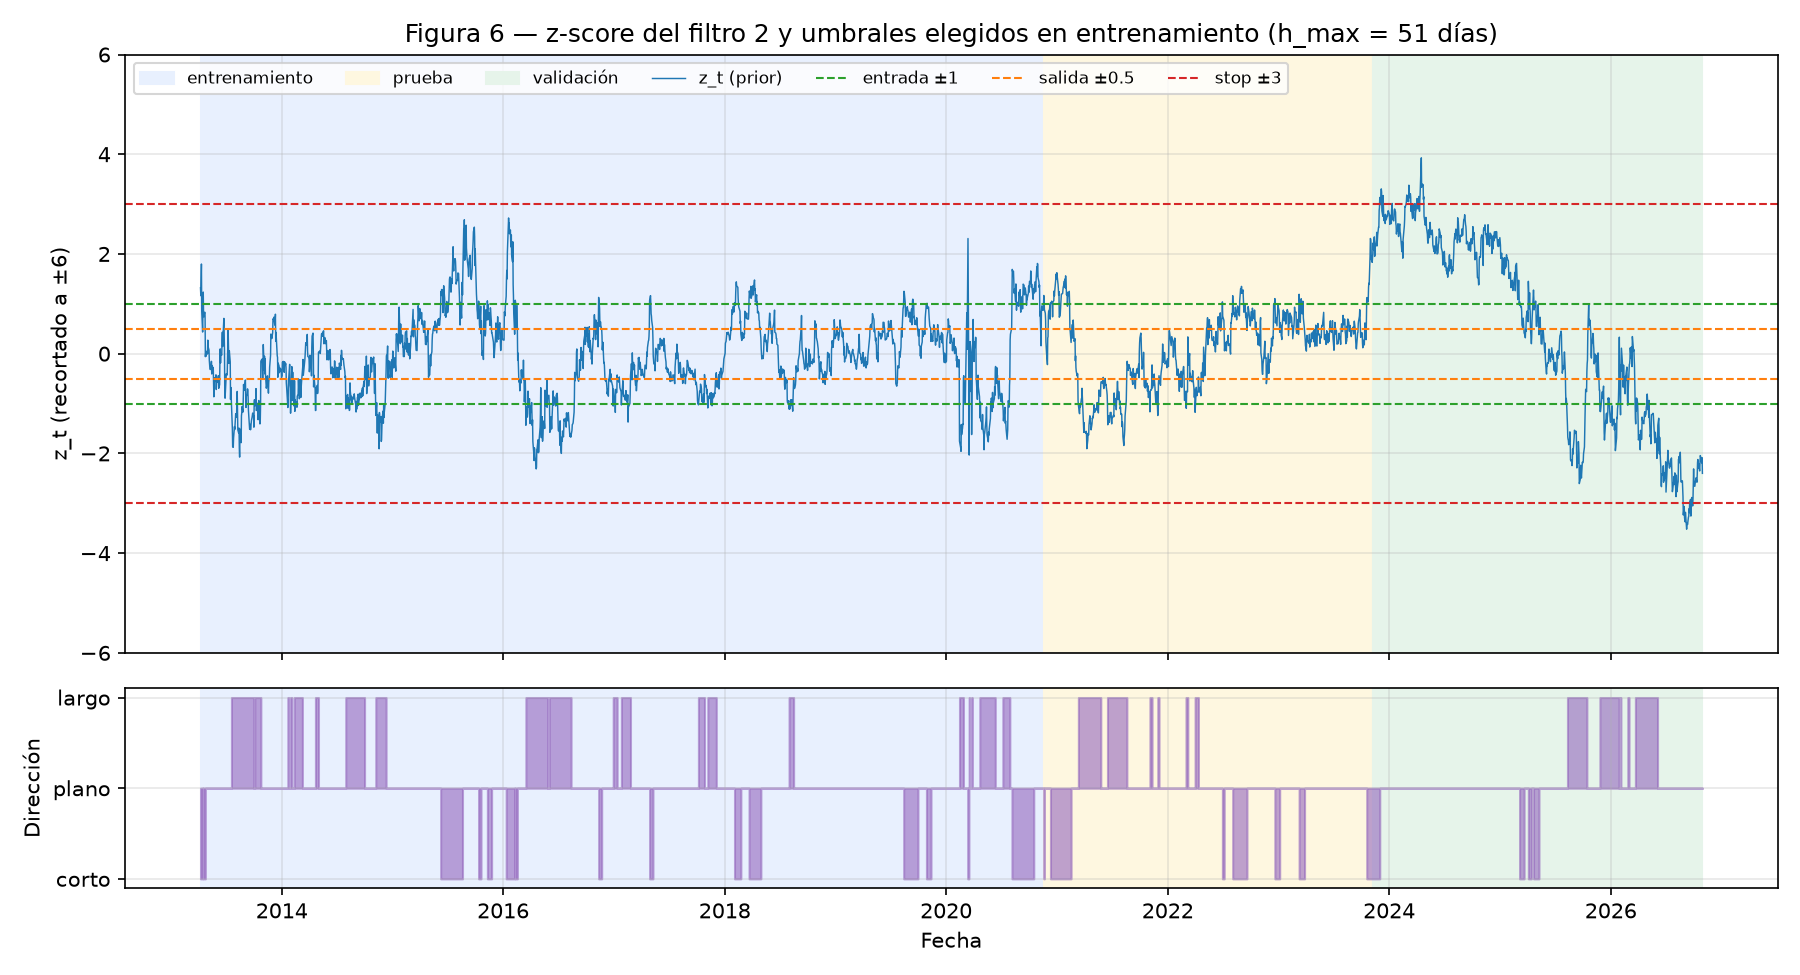

Días con posición por partición:
split
train         34%
test          31%
validation    25%
Motivos de cierre decididos por la regla:
split       exit_reason
train       salida         30
            holding         5
test        salida         10
            holding         1
validation  stop            1
            salida          7
            holding         1


In [9]:
display(Image(FIGURES / "fig06_zscore_umbrales.png"))
print("Días con posición por partición:")
print(signals.groupby("split", sort=False)["signal"].apply(lambda s: f"{(s != 0).mean():.0%}").to_string())
print("Motivos de cierre decididos por la regla:")
print(signals.loc[signals["exit_reason"] != ""].groupby(["split", "exit_reason"], sort=False).size().to_string())

## 8. Vista previa fuera de muestra con θ congelado

Cada partición arranca plana con $1,000,000 y cierra al final. Esto es solo una **vista previa** para defender la
regla; la evaluación oficial (curva de capital, bitácora y métricas) es la parte 06 (`backtest/walk_forward.py`).

In [10]:
preview = evaluate_by_split(prices, signals, rule)
display(preview[["sharpe_net", "net_return", "max_drawdown", "n_trades", "win_rate", "avg_days", "exposure",
                 "exits_salida", "exits_stop", "exits_holding", "exits_fin_particion"]])

,sharpe_net,net_return,max_drawdown,n_trades,win_rate,avg_days,exposure,exits_salida,exits_stop,exits_holding,exits_fin_particion
split,,,,,,,,,,,
train,0.7709,0.2389,-0.03867,35,0.8,18.57,0.3382,30,0,5,0
test,0.331,0.02368,-0.02172,12,0.75,19.17,0.3083,10,0,1,1
validation,0.3871,0.0286,-0.02618,9,0.6667,20.67,0.2493,7,1,1,0


## 9. Backtest con el ECT estático contra el dinámico (sugerencia del profesor)

A cada ECT se le calibra su propio filtro 2 en train y se le aplica **el mismo θ**. El estático dimensiona con el β̃ fijo
de Johansen y el dinámico con β̂_t del filtro 1.

In [11]:
comparison = compare_static_dynamic(prices, kf1, johansen["beta_normalized"], rule)
display(comparison[["sharpe_net", "net_return", "max_drawdown", "n_trades", "exits_stop", "kf2_half_life"]])

sharpe_net  net_return  max_drawdown  n_trades  exits_stop  kf2_half_life
ect     split                                                                                
dynamic train           0.7709      0.2389      -0.03867        35           0          21.18
        test             0.331     0.02368      -0.02172        12           0          21.18
        validation      0.3871      0.0286      -0.02618         9           1          21.18
static  train           0.7459      0.2296       -0.0372        32           0          24.51
        test           0.09748    0.006931       -0.0217         9           0          24.51
        validation     -0.5944    -0.01694      -0.02591         2           1          24.51

En train los dos son casi iguales, porque ahí la relación de Johansen es la verdadera. Fuera de muestra el estático se
degrada: su ECT se desplaza y el filtro 2 lo interpreta como desviación. El dinámico absorbe parte del cambio en β̂_t y
mantiene el ECT más centrado (media 0.11 contra 0.44 en validación). Ojo: en validación **ninguno** de los dos pasa
ADF (sección 2); la relación se debilita, y el dinámico pierde menos por eso. Es la razón de usar el filtro 1.

## 10. Causalidad (prueba 1, `tests/test_causality.py`)

La prueba recalcula todo el pipeline con datos solo hasta t, para tres fechas posteriores al fin de train (2020-11-19):
2021-03-15, 2024-06-14 y 2026-09-15. El pipeline incluye Johansen, la calibración y corrida de ambos filtros, el VECM,
el grid search y la regla. Comprueba que la calibración, z_t y la señal en t (y en todos los días anteriores) sean
idénticos a los de la corrida completa. Además, la regla recorre z hacia adelante y el motor ejecuta en t + 1.

## Resumen de resultados (parte 05)

| Resultado | Valor |
|---|---|
| VECM (train) | r = 1, k_ar_diff = 1, constante sin restringir; β = β̃ de Johansen |
| α | GLD −0.015 (t = −3.2, el único significativo); GDX +0.004, AEM −0.010, FNV +0.013 (no significativos) |
| βᵀα | −0.026 → corrige (−2 < βᵀα < 0); vida media del VECM 26.4 días (Johansen 25.3, filtro 2 21.2) |
| Interpretación | Cuando el spread se abre, **el oro corrige** hacia las mineras |
| Regla | PFA de bandas sobre z prior: stop > holding > salida direccional; rearme tras stop o holding |
| Grid (train) | 207 combinaciones, 153 con ≥ 10 operaciones; objetivo: Sharpe neto con costos y rebalanceo diario |
| θ elegido | z_entrada 1.0, z_salida 0.5, z_stop 3.0, h_max 51 días (2 vidas medias) |
| Train | Sharpe neto 0.77, rendimiento 23.9 %, 35 operaciones, 80 % ganadoras; comisiones = 26 % del P&L bruto |
| Vista previa | Sharpe neto 0.33 en prueba y 0.39 en validación (con θ congelado) |
| Estático vs dinámico | mismo θ: estático 0.10 / −0.59 en prueba / validación, dinámico 0.33 / 0.39 |
| Causalidad | pipeline truncado en 3 fechas posteriores a train → mismo z_t y misma señal |

- **Limitaciones:**
  - El óptimo de z_entrada está en el borde inferior de la rejilla, que no se amplió.
  - En train el stop nunca se activa, así que su valor se eligió por desempate y no por desempeño.
  - Las comisiones de 4 patas con rebalanceo diario pesan mucho; la parte 06 compara contra la banda.
- **Hallazgo:** el stop más el rearme son lo que evita pérdidas grandes en validación, donde la relación se desplaza.